# Fase 3 — Análisis Exploratorio de Datos (EDA)

## Objetivo
Entender el comportamiento histórico de nuestra cesta de 4 ETFs (SPY, QQQ, TLT, GLD) durante los últimos 10 años, identificar regímenes de mercado y buscar estructura predecible (o su ausencia) antes de construir modelos.

## ¿Por qué estos 4 activos?
Cubren 4 clases de activos y regímenes distintos, lo que permite construir carteras diversificadas y probar al agente RL en escenarios muy variados:
- **SPY**: Renta variable general EE.UU. (S&P 500).
- **QQQ**: Renta variable tecnológica (Nasdaq 100), mayor beta y volatilidad.
- **TLT**: Bonos del Tesoro a largo plazo (20+ años), refugio en deflación y sensible a tipos de interés.
- **GLD**: Oro, refugio clásico en crisis e inflación.

## Estructura
- **§1** Carga de datos y calidad.
- **§2** Estadísticas descriptivas y rentabilidad/riesgo.
- **§3** Visualización de precios y regímenes.
- **§4** Distribución de retornos.
- **§5** Matriz de correlaciones.
- **§6** Autocorrelación: ¿hay señal predecible?
- **§7** Conclusiones para el modelado.

In [1]:
import sys
sys.path.append("../src")

import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:.4f}".format)

# Cargar dataset EDA (generado en Fase 3 con adj_close, log_ret y vol rolling)
DATA_PATH = Path("../data/processed/dataset_eda.csv")
df = pd.read_csv(DATA_PATH, parse_dates=["Date"])

TICKERS = ["GLD", "QQQ", "SPY", "TLT"]
print(f"Dataset shape: {df.shape}")
print(f"Rango temporal: {df['Date'].min().date()} -> {df['Date'].max().date()}")
print(f"Tickers: {sorted(df['Ticker'].unique())}")

Dataset shape: (11060, 12)
Rango temporal: 2015-01-02 -> 2025-12-30
Tickers: ['GLD', 'QQQ', 'SPY', 'TLT']


## §1 Carga de datos y calidad

Verificamos que todos los activos tienen el mismo número de sesiones y no hay huecos temporales graves (ej. días de trading distintos entre EE.UU. y España, aunque al ser todos ETFs de EE.UU. deberían estar alineados).

In [2]:
coverage = df.groupby("Ticker").agg(
    n_sesiones=("Date", "count"),
    primera=("Date", "min"),
    ultima=("Date", "max"),
    nan_close=("Adj_Close", lambda s: s.isna().sum()),
).reset_index()

print("Cobertura por ticker:")
print(coverage.to_string(index=False))

Cobertura por ticker:
Ticker  n_sesiones    primera     ultima  nan_close
   GLD        2765 2015-01-02 2025-12-30          0
   QQQ        2765 2015-01-02 2025-12-30          0
   SPY        2765 2015-01-02 2025-12-30          0
   TLT        2765 2015-01-02 2025-12-30          0


## §2 Estadísticas descriptivas y rentabilidad/riesgo

Anualizamos los retornos logarítmicos (media × 252) y la volatilidad (std × √252) para tener una visión clara del binomio rentabilidad-riesgo de cada activo.

In [3]:
stats = df.groupby("Ticker")["log_ret"].agg(
    media_diaria="mean",
    std_diaria="std",
    skewness="skew",
    kurtosis=lambda s: s.kurtosis(),
    min="min",
    max="max",
).reset_index()

# Anualizar
stats["ret_anual_%"] = stats["media_diaria"] * 252 * 100
stats["vol_anual_%"] = stats["std_diaria"] * np.sqrt(252) * 100
stats["sharpe_naive"] = stats["ret_anual_%"] / stats["vol_anual_%"]

cols = ["Ticker", "ret_anual_%", "vol_anual_%", "sharpe_naive", "skewness", "kurtosis", "min", "max"]
print(stats[cols].round(3).to_string(index=False))
print("\nNota: la kurtosis > 3 en todos los activos confirma 'fat tails' (colas gruesas), típico de series financieras.")

Ticker  ret_anual_%  vol_anual_%  sharpe_naive  skewness  kurtosis     min    max
   GLD      11.4130      14.7570        0.7730   -0.2510    3.3440 -0.0660 0.0480
   QQQ      17.1150      22.0160        0.7770   -0.3930    7.7960 -0.1280 0.1130
   SPY      12.7010      17.8330        0.7120   -0.5840   14.5700 -0.1160 0.1000
   TLT      -0.6890      15.0380       -0.0460   -0.0010    4.4040 -0.0690 0.0730

Nota: la kurtosis > 3 en todos los activos confirma 'fat tails' (colas gruesas), típico de series financieras.


## §3 Precios y regímenes de mercado

Normalizamos los precios a base 100 (primer día = 100) para comparar la evolución de los 4 activos. 

Esto nos permite identificar visualmente los grandes regímenes macroeconómicos del periodo 2015-2025:
- **2018**: Corrección de Powell (tipos altos).
- **2020**: Crash del COVID y recuperación con estímulos.
- **2022**: Inflación y subida de tipos (el peor año para bonos y acciones).
- **2024-2025**: Rally del oro e incertidumbre geopolítica.

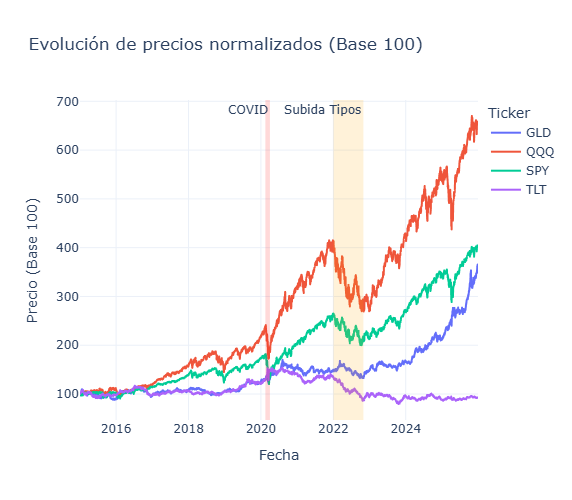

In [4]:
# Normalizar a base 100
df_norm = df.copy()
for t in TICKERS:
    mask = df_norm["Ticker"] == t
    base_price = df_norm.loc[mask, "Adj_Close"].iloc[0]
    df_norm.loc[mask, "price_norm"] = (df_norm.loc[mask, "Adj_Close"] / base_price) * 100

fig = px.line(
    df_norm, x="Date", y="price_norm", color="Ticker",
    title="Evolución de precios normalizados (Base 100)",
    labels={"price_norm": "Precio (Base 100)", "Date": "Fecha"},
)
fig.add_vrect(x0="2020-02-15", x1="2020-04-01", fillcolor="red", opacity=0.15, line_width=0, annotation_text="COVID")
fig.add_vrect(x0="2022-01-01", x1="2022-10-31", fillcolor="orange", opacity=0.15, line_width=0, annotation_text="Subida Tipos")
fig.update_layout(template="plotly_white", height=500)
fig.show()

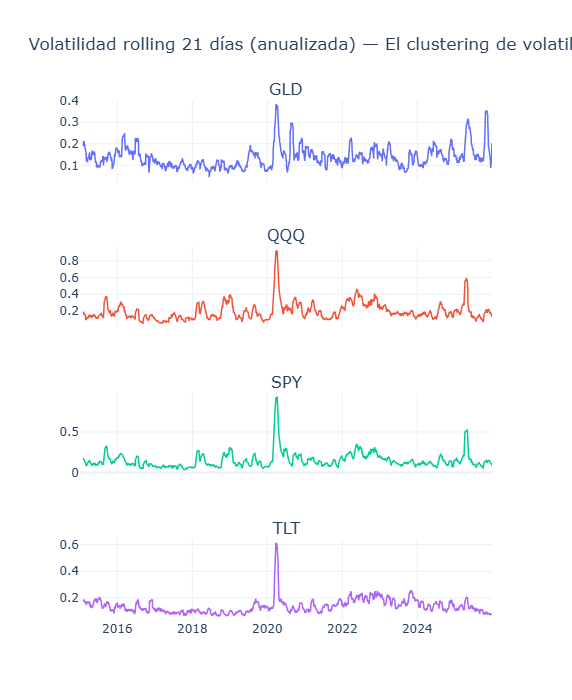

In [5]:
fig = make_subplots(rows=4, cols=1, subplot_titles=TICKERS, shared_xaxes=True)
for i, t in enumerate(TICKERS, 1):
    sub = df[df["Ticker"] == t]
    fig.add_trace(go.Scatter(x=sub["Date"], y=sub["vol_21d"], name=f"{t} 21d", line=dict(width=1.5)), row=i, col=1)
fig.update_layout(
    title="Volatilidad rolling 21 días (anualizada) — El clustering de volatilidad es evidente",
    template="plotly_white", height=700, showlegend=False,
)
fig.show()

## §4 Distribución de retornos

Los retornos diarios **no siguen una distribución normal**. Tienen colas más gruesas (eventos extremos ocurren más de lo que predice la campana de Gauss). Esto es crucial: un agente RL que asuma normalidad sufrirá en los días de pánico.

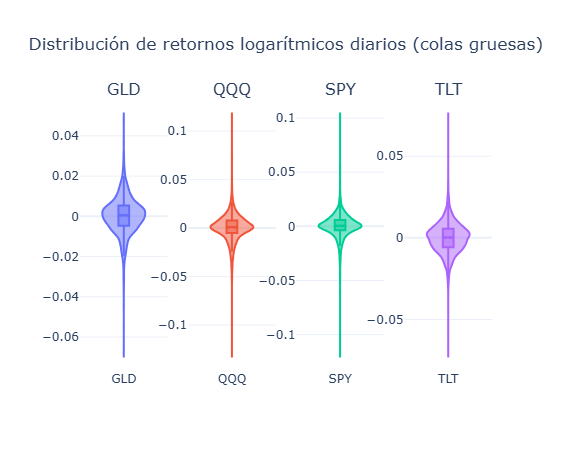

In [6]:
fig = make_subplots(rows=1, cols=4, subplot_titles=TICKERS)
for i, t in enumerate(TICKERS, 1):
    sub = df[df["Ticker"] == t]["log_ret"].dropna()
    fig.add_trace(
        go.Violin(y=sub, name=t, box_visible=True, meanline_visible=True, points=False),
        row=1, col=i,
    )
fig.update_layout(
    title="Distribución de retornos logarítmicos diarios (colas gruesas)",
    template="plotly_white", height=450, showlegend=False,
)
fig.show()

## §5 Matriz de correlaciones

Una cartera diversificada requiere activos con baja correlación. En días normales, SPY y QQQ están fuertemente correlacionados. Sin embargo, en crisis, las correlaciones suelen dispararse (todo cae a la vez), excepto el oro (GLD) o los bonos (TLT), que pueden actuar como refugio.

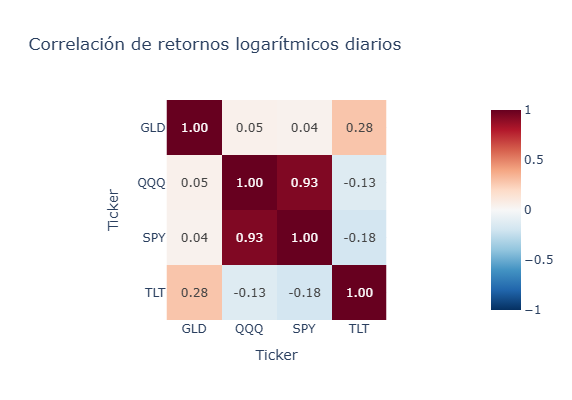

In [7]:
pivot = df.pivot_table(index="Date", columns="Ticker", values="log_ret")
corr = pivot.corr()

fig = px.imshow(
    corr, text_auto=".2f", color_continuous_scale="RdBu_r",
    title="Correlación de retornos logarítmicos diarios",
    zmin=-1, zmax=1,
)
fig.update_layout(template="plotly_white", height=400)
fig.show()

## §6 ¿Hay señal predecible? (Autocorrelación)

Esta es **la sección más importante del EDA**. 

Si los retornos de hoy no tienen relación con los de ayer (autocorrelación ≈ 0), el mercado es una "camina aleatoria" y predecirlo es imposible.

Si hay **autocorrelación negativa**, significa que hay **mean reversion** (si hoy sube, mañana tiende a bajar). Esta es la señal que intentaremos explotar con los modelos de Fase 5 y el agente RL.

In [9]:
print("Autocorrelación de log_ret (lag 1 a 5):")
acf_rows = []
for t in TICKERS:
    s = df[df["Ticker"] == t]["log_ret"].dropna()
    row = {"Ticker": t}
    for lag in [1, 2, 3, 4, 5]:
        row[f"lag_{lag}"] = s.autocorr(lag=lag)
    acf_rows.append(row)

acf_df = pd.DataFrame(acf_rows)
print(acf_df.round(4).to_string(index=False))

print("\nInterpretación:")
print("  - SPY y QQQ tienen autocorrelación lag-1 negativa fuerte (~ -0.12).")
print("  - GLD y TLT tienen autocorrelación ~ 0 (camino aleatorio puro).")
print("  - Conclusión: hay mean-reversion de corto plazo en renta variable USA.")

Autocorrelación de log_ret (lag 1 a 5):
Ticker   lag_1   lag_2   lag_3   lag_4   lag_5
   GLD  0.0010 -0.0197  0.0153  0.0011 -0.0283
   QQQ -0.1071  0.0403 -0.0364 -0.0373  0.0203
   SPY -0.1191  0.0717 -0.0279 -0.0638  0.0400
   TLT -0.0230 -0.0831 -0.0332  0.0108  0.0283

Interpretación:
  - SPY y QQQ tienen autocorrelación lag-1 negativa fuerte (~ -0.12).
  - GLD y TLT tienen autocorrelación ~ 0 (camino aleatorio puro).
  - Conclusión: hay mean-reversion de corto plazo en renta variable USA.


## §7 Conclusiones del EDA (y motivación para las siguientes fases)

1. **Regímenes claros**: El periodo 2015-2025 contiene múltiples crisis (2018, 2020, 2022), lo que es ideal para entrenar y evaluar un agente RL robusto.
2. **Fat tails**: Los retornos tienen colas gruesas. El RL deberá aprender a protegerse en días extremos, no solo a maximizar el retorno medio.
3. **Diversificación**: La matriz de correlación muestra que GLD y TLT no están perfectamente correlacionados con SPY/QQQ, lo que justifica una cartera multi-activo.
4. **Señal predecible (Mean Reversion)**: SPY y QQQ muestran autocorrelación negativa en lag-1. Esto valida la hipótesis de que un modelo predictivo (Fase 5) o un agente RL (Fase 6) **pueden** encontrar estructura y generar alpha.
5. **Volatilidad agrupada**: Los periodos de alta volatilidad se agrupan. El agente necesitará features de volatilidad rolling para saber cuándo reducir exposición (o usar cash).

**Próximo paso**: Fase 4 — Feature Engineering. Construiremos RSI, MACD y Bollinger para intentar capturar esa mean reversion.